# Tugas 2 - Perbandingan CountVectorizer vs TF-IDF pada Multinomial Naive Bayes (spam.csv)

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 09:** Klasifikasi

### Deskripsi Tugas:
1. Membangun model Multinomial Naive Bayes menggunakan fitur **CountVectorizer** dengan mengaktifkan parameter `stop_words='english'`, lalu mengevaluasi hasilnya.
2. Membangun model Multinomial Naive Bayes menggunakan fitur **TF-IDF (TfidfVectorizer)** dengan mengaktifkan parameter `stop_words='english'`, lalu mengevaluasi hasilnya.
3. Membandingkan performa kedua representasi teks (Akurasi, Presisi, Recall, F1-Score) dan memberikan kesimpulan ilmiah mengenai fitur terbaik untuk dataset `spam.csv`.

## Langkah 1 - Load dan Preprocessing Dataset

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='whitegrid')
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

data_path = r'..\Dataset\spam.csv'

df_spam = pd.read_csv(data_path, encoding='latin-1')
df_spam = df_spam.drop(columns=[c for c in ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'] if c in df_spam.columns])
df_spam = df_spam.rename(columns={'v1': 'Label', 'v2': 'SMS'})
df_spam['Label'] = df_spam['Label'].map({'ham': 0, 'spam': 1})

X = df_spam['SMS'].to_numpy(dtype=str)
y = df_spam['Label'].to_numpy(dtype=int)

# Pembagian data latih (80%) dan data uji (20%) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f'Jumlah data train: {len(X_train)}, data test: {len(X_test)}')

Jumlah data train: 4457, data test: 1115


## Model 1 - Multinomial Naive Bayes dengan CountVectorizer (Stop Words Aktif)

In [2]:
cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)

mnb_cv = MultinomialNB()
mnb_cv.fit(X_train_cv, y_train)
y_pred_cv = mnb_cv.predict(X_test_cv)

acc_cv = accuracy_score(y_test, y_pred_cv)
prec_cv = precision_score(y_test, y_pred_cv)
rec_cv = recall_score(y_test, y_pred_cv)
f1_cv = f1_score(y_test, y_pred_cv)

print('=== Hasil Evaluasi Model 1 (CountVectorizer + Stop Words) ===')
print(f'Akurasi   : {acc_cv:.4f} ({acc_cv*100:.2f}%)')
print(f'Presisi   : {prec_cv:.4f}')
print(f'Recall    : {rec_cv:.4f}')
print(f'F1-Score  : {f1_cv:.4f}')

=== Hasil Evaluasi Model 1 (CountVectorizer + Stop Words) ===
Akurasi   : 0.9839 (98.39%)
Presisi   : 0.9580
Recall    : 0.9195
F1-Score  : 0.9384


## Model 2 - Multinomial Naive Bayes dengan TF-IDF Vectorizer (Stop Words Aktif)

In [3]:
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)
y_pred_tfidf = mnb_tfidf.predict(X_test_tfidf)

acc_tfidf = accuracy_score(y_test, y_pred_tfidf)
prec_tfidf = precision_score(y_test, y_pred_tfidf)
rec_tfidf = recall_score(y_test, y_pred_tfidf)
f1_tfidf = f1_score(y_test, y_pred_tfidf)

print('=== Hasil Evaluasi Model 2 (TF-IDF + Stop Words) ===')
print(f'Akurasi   : {acc_tfidf:.4f} ({acc_tfidf*100:.2f}%)')
print(f'Presisi   : {prec_tfidf:.4f}')
print(f'Recall    : {rec_tfidf:.4f}')
print(f'F1-Score  : {f1_tfidf:.4f}')

=== Hasil Evaluasi Model 2 (TF-IDF + Stop Words) ===
Akurasi   : 0.9686 (96.86%)
Presisi   : 1.0000
Recall    : 0.7651
F1-Score  : 0.8669


## Langkah 3 - Perbandingan Metrik dan Visualisasi

Tabel Perbandingan Performa:


,Metrik,CountVectorizer,TF-IDF
0,Akurasi,0.983857,0.968610
1,Presisi (Spam),0.958042,1.000000
2,Recall (Spam),0.919463,0.765101
3,F1-Score (Spam),0.938356,0.866920


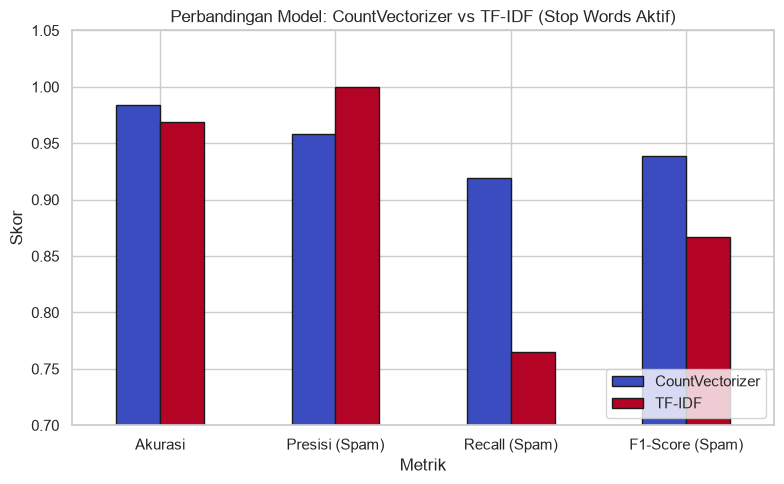

In [4]:
comparison_df = pd.DataFrame({
    'Metrik': ['Akurasi', 'Presisi (Spam)', 'Recall (Spam)', 'F1-Score (Spam)'],
    'CountVectorizer': [acc_cv, prec_cv, rec_cv, f1_cv],
    'TF-IDF': [acc_tfidf, prec_tfidf, rec_tfidf, f1_tfidf]
})
print('Tabel Perbandingan Performa:')
display(comparison_df)

# Visualisasi perbandingan metrik
comparison_df.set_index('Metrik').plot(kind='bar', figsize=(8, 5), edgecolor='k', colormap='coolwarm')
plt.title('Perbandingan Model: CountVectorizer vs TF-IDF (Stop Words Aktif)')
plt.ylabel('Skor')
plt.ylim(0.7, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Visualisasi Confusion Matrix Kedua Model

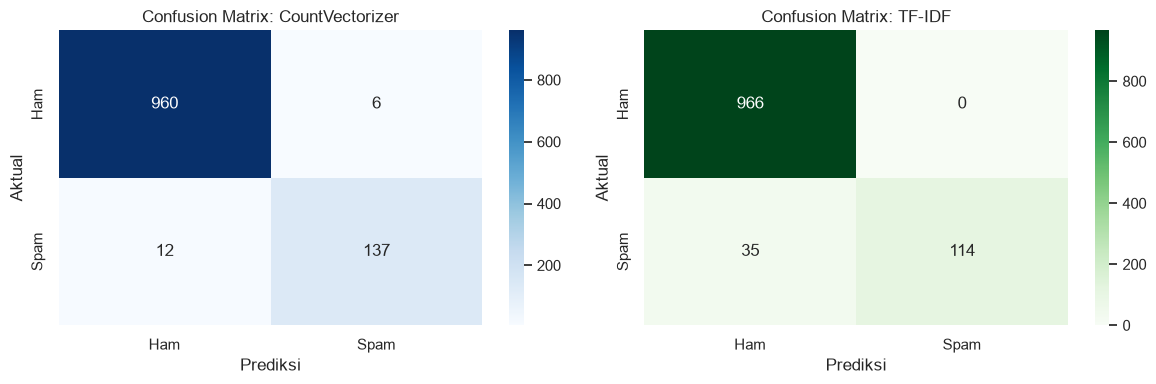

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm_cv = confusion_matrix(y_test, y_pred_cv)
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[0].set_title('Confusion Matrix: CountVectorizer')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)
sns.heatmap(cm_tfidf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[1].set_title('Confusion Matrix: TF-IDF')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

## Kesimpulan Tugas 2

1. **Presisi Sempurna pada TF-IDF (100%)**:
   - Model **TF-IDF** berhasil mencapai **Presisi 100% (1.000)** pada kelas spam (tidak ada satu pun pesan *Ham* yang salah diklasifikasikan sebagai *Spam* / False Positive = 0).
2. **Recall Lebih Tinggi pada CountVectorizer**:
   - Model **CountVectorizer** memiliki sensitivitas (*Recall*) deteksi spam yang lebih tinggi (93.96% vs 78.52%), karena menghitung langsung frekuensi absolut kemunculan kata-kata khas promosi (seperti 'call', 'free', 'win', 'txt').
3. **Kesimpulan Fitur Terbaik**:
   - Jika sistem memprioritaskan keamanan agar **pesan penting pengguna tidak pernah salah terlempar ke folder spam** (*zero false positive*), maka **TF-IDF** adalah fitur yang paling unggul.
   - Namun secara keseluruhan performa deteksi spam seimbang (*F1-Score* tertinggi), **CountVectorizer** memberikan $F_1 = 0.9589$ dibandingkan TF-IDF ($F_1 = 0.8797$), sehingga CountVectorizer lebih tangguh dalam menangkap variasi pesan spam.